Для начала импортируем библиотеки:

In [1]:
#!pip install -r requirements.txt

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from src import simulation, SCENARIOS, INDEX_FILES, DATA_DIR, load_index, index_metrics, print_index_metrics
from src.plotting import plot_price, plot_wealth_history, plot_wealth_histograms, plot_trader_counts

SEED = 0     # re-seeded before every scenario, so each run is reproducible on its own
DAYS = 1000

The market and the agents are defined once in the `src/` package, and every scenario below runs that code:

- `src/asset.py` — `Asset`: price, dividend random walk, optional circuit breaker;
- `src/order_book.py` — `OrderBook`: order matching, no borrowing (balances can't go negative);
- `src/traders.py` — `NoiseTrader`, `ChartistTrader`, `FundamentalistTrader`;
- `src/metrics.py` — Hurst (R/S), Rosenstein λ and Sample Entropy via `nolds`;
- `src/scenarios.py` — trader counts, endowments and switches for each scenario;
- `src/simulation.py` — `run_simulation(scenario, days)`.

Earlier versions of this notebook redefined all classes inside each scenario cell (see git commit `84fa2a6`). `tests/test_legacy_equivalence.py` checks that, for the same `np.random.seed`, the package reproduces those cells exactly.

Запустим обучение и взглянем на результаты:


Day 0: Price = 101.14
Active Traders - Noise: 50/50, Chartist: 20/20, Fundamentalist: 30/30
Noise Traders: Avg Cash = 98989.69, Avg Assets = 1010.00, Avg Wealth = 201140.41
Chartist Traders: Avg Cash = 152525.77, Avg Assets = 975.00, Avg Wealth = 251136.61
Fundamentalist Traders: Avg Cash = 1000000.00, Avg Assets = 500.00, Avg Wealth = 1050569.66

Day 100: Price = 69.97
Active Traders - Noise: 50/50, Chartist: 20/20, Fundamentalist: 30/30
Noise Traders: Avg Cash = 123847.64, Avg Assets = 656.20, Avg Wealth = 169762.17
Chartist Traders: Avg Cash = 161438.14, Avg Assets = 839.50, Avg Wealth = 220178.24
Fundamentalist Traders: Avg Cash = 952628.51, Avg Assets = 1180.00, Avg Wealth = 1035193.50

Day 200: Price = 135.35
Active Traders - Noise: 50/50, Chartist: 20/20, Fundamentalist: 30/30
Noise Traders: Avg Cash = 171511.21, Avg Assets = 88.54, Avg Wealth = 183494.70
Chartist Traders: Avg Cash = 171392.25, Avg Assets = 644.30, Avg Wealth = 258595.40
Fundamentalist Traders: Avg Cash = 86655

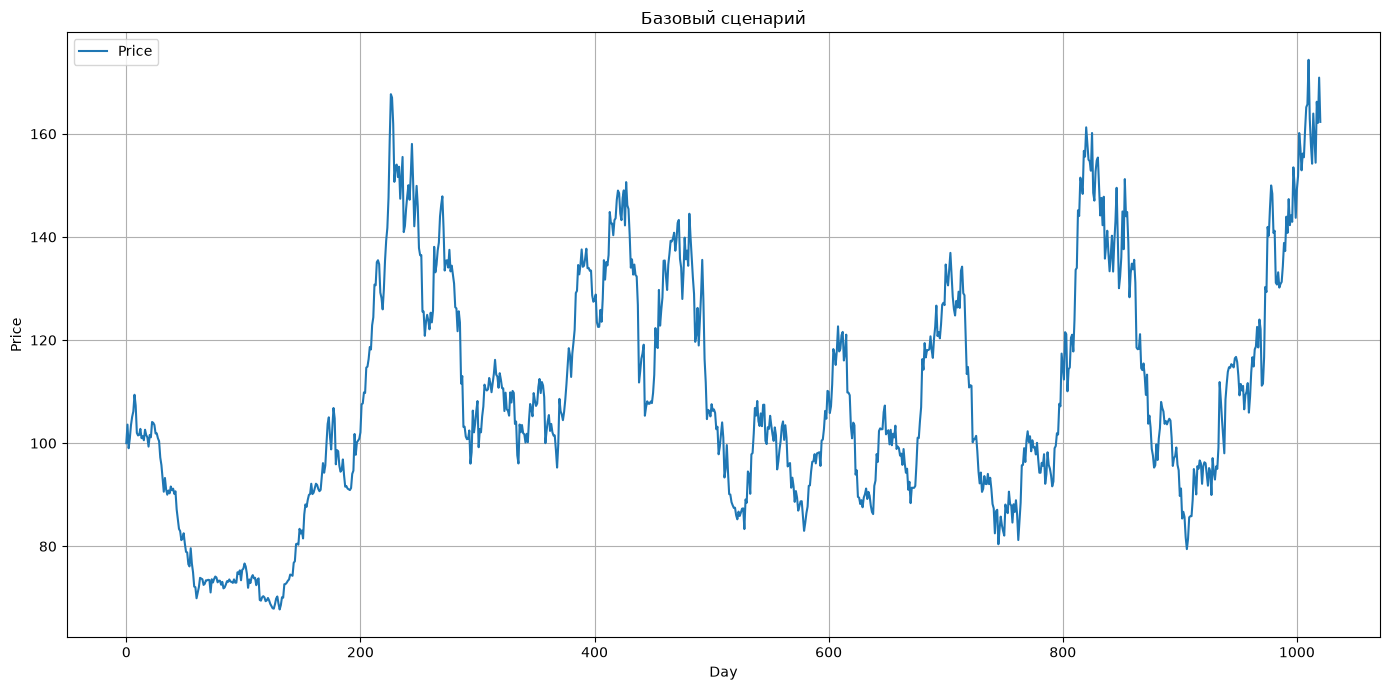

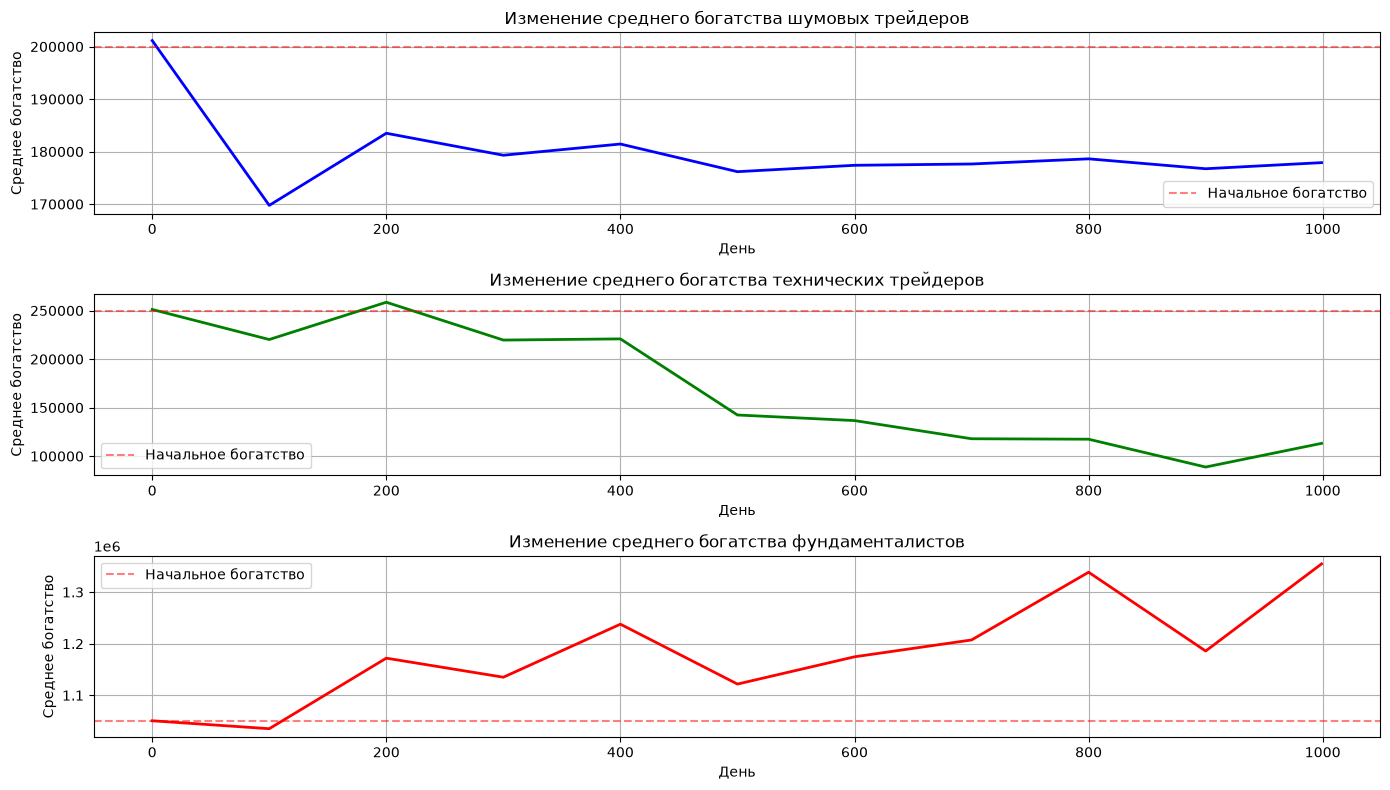

In [3]:
np.random.seed(SEED)
asset, traders = simulation.run_simulation(SCENARIOS['baseline'], days=DAYS)
plot_price(asset, title=SCENARIOS['baseline'].title)
plot_wealth_history(simulation.wealth_history)
plt.show()

Теперь взглянем на гистограммы распределений совоккупного богатства у различных типов агентов:

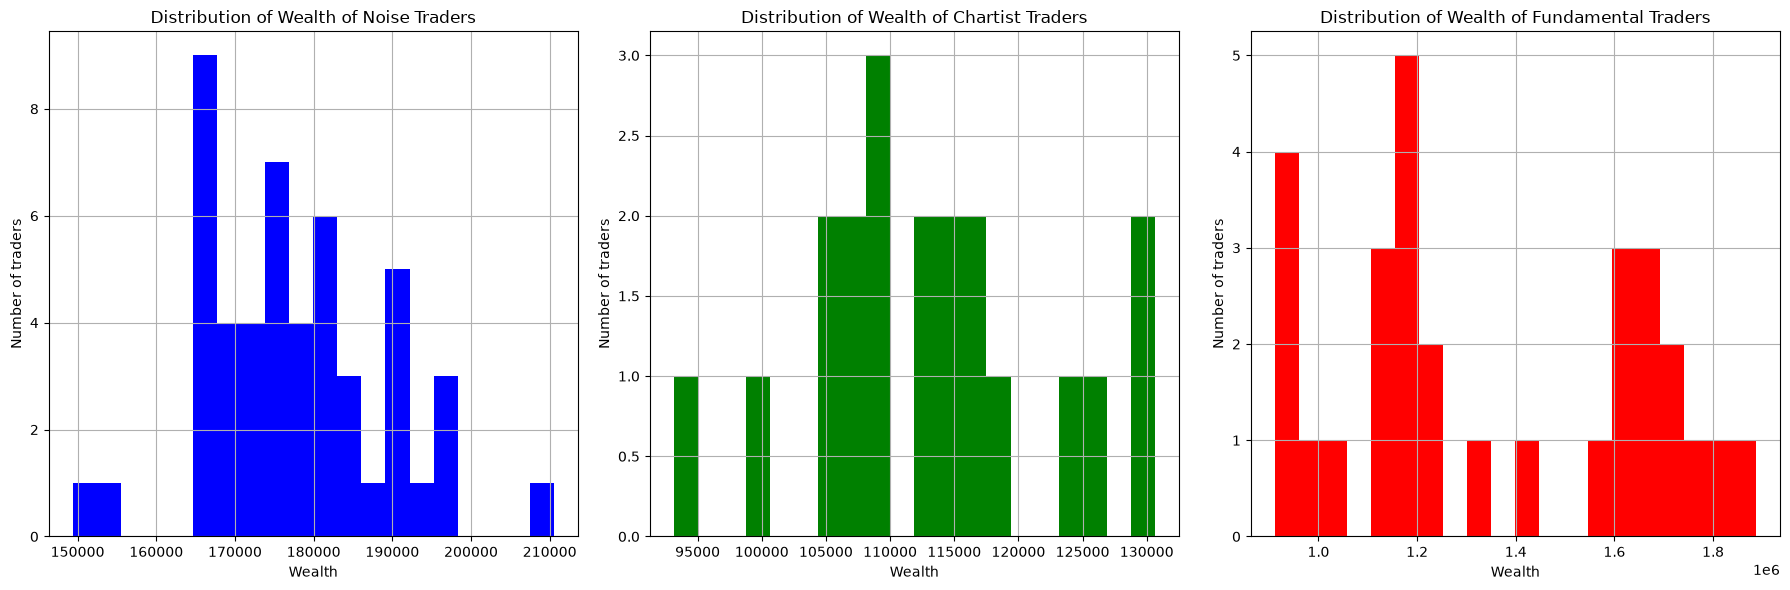

In [4]:
plot_wealth_histograms(traders)
plt.show()

Модифицируем агентную модель и увеличим количество шумовых трейдеров в 10 раз:


Day 0: Price = 101.43
Active Traders - Noise: 500/500, Chartist: 20/20, Fundamentalist: 30/30
Noise Traders: Avg Cash = 99777.48, Avg Assets = 1002.20, Avg Wealth = 201428.29
Chartist Traders: Avg Cash = 155563.09, Avg Assets = 945.00, Avg Wealth = 251412.24
Fundamentalist Traders: Avg Cash = 1000000.00, Avg Assets = 500.00, Avg Wealth = 1050713.84

Day 100: Price = 77.02
Active Traders - Noise: 500/500, Chartist: 20/20, Fundamentalist: 30/30
Noise Traders: Avg Cash = 96246.68, Avg Assets = 1039.51, Avg Wealth = 176309.63
Chartist Traders: Avg Cash = 243832.99, Avg Assets = 12.20, Avg Wealth = 244772.64
Fundamentalist Traders: Avg Cash = 1000000.00, Avg Assets = 500.00, Avg Wealth = 1038509.87

Day 200: Price = 61.34
Active Traders - Noise: 500/500, Chartist: 20/20, Fundamentalist: 30/30
Noise Traders: Avg Cash = 96210.21, Avg Assets = 1040.00, Avg Wealth = 160002.31
Chartist Traders: Avg Cash = 244744.72, Avg Assets = 0.00, Avg Wealth = 244744.72
Fundamentalist Traders: Avg Cash = 10

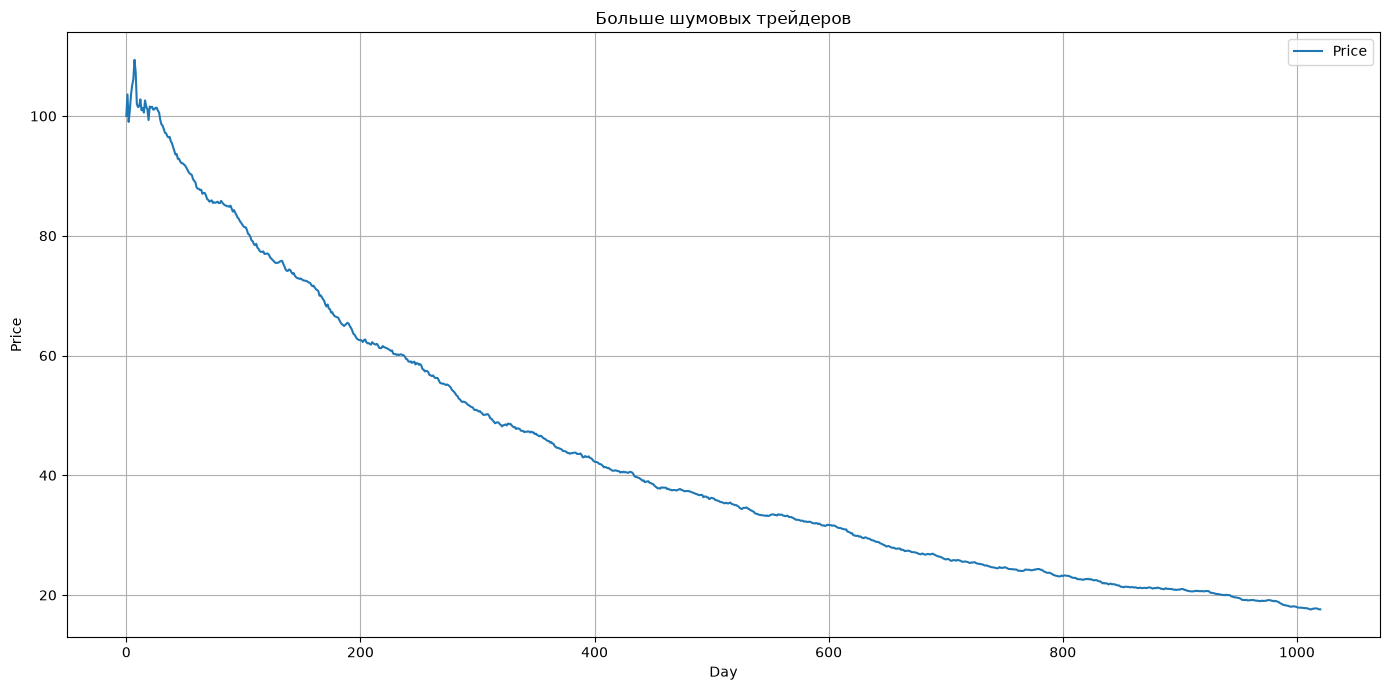

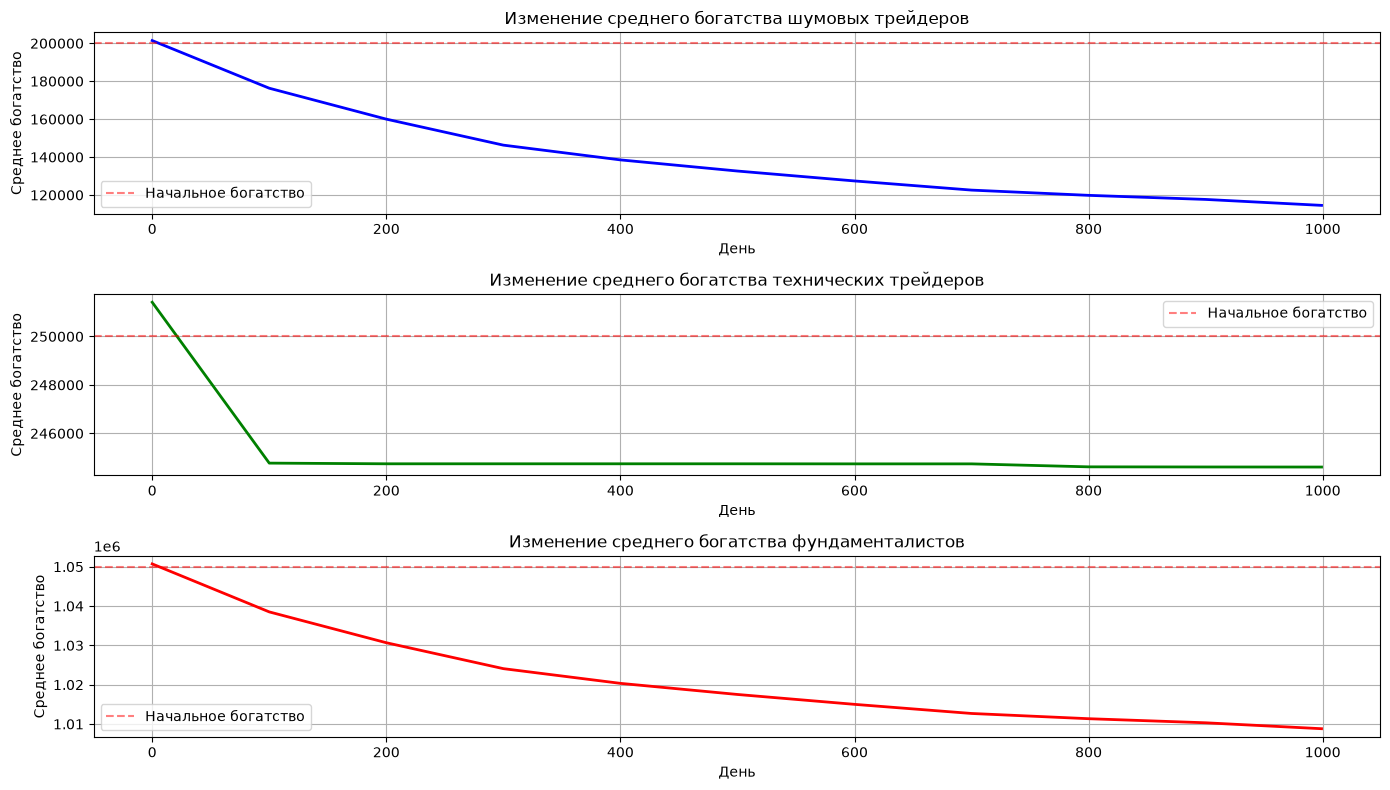

In [5]:
np.random.seed(SEED)
asset, traders = simulation.run_simulation(SCENARIOS['more_noise'], days=DAYS)
plot_price(asset, title=SCENARIOS['more_noise'].title)
plot_wealth_history(simulation.wealth_history)
plt.show()

Взглянем на гистограммы распределений совокупного богатства у различных типов агентов:

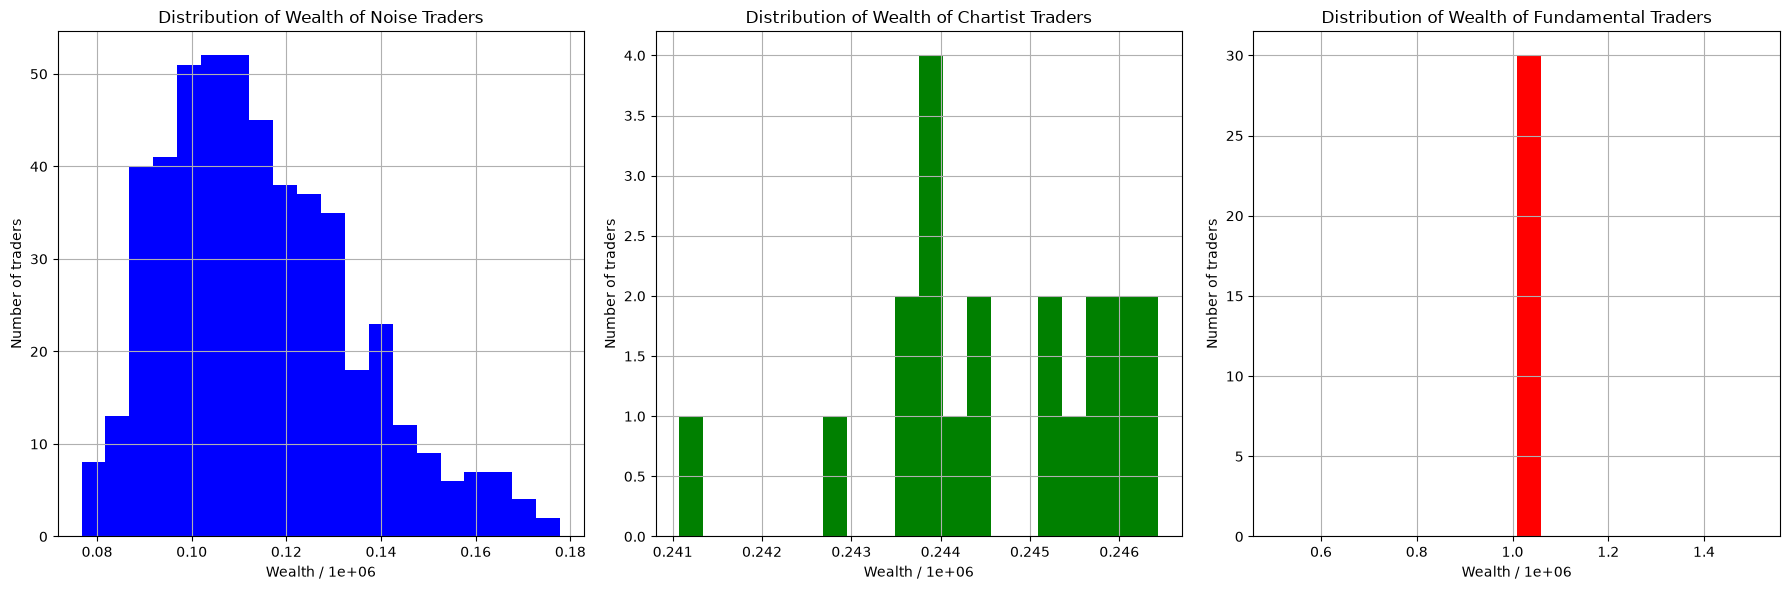

In [6]:
plot_wealth_histograms(traders, scale=1e6)
plt.show()

Теперь запустим обучение, в котором будет раздуто количество технических трейдеров:


Day 0: Price = 100.44
Active Traders - Noise: 25/25, Chartist: 130/130, Fundamentalist: 15/15
Noise Traders: Avg Cash = 100000.00, Avg Assets = 1000.00, Avg Wealth = 200439.59
Chartist Traders: Avg Cash = 150000.00, Avg Assets = 1000.00, Avg Wealth = 250439.59
Fundamentalist Traders: Avg Cash = 1000000.00, Avg Assets = 500.00, Avg Wealth = 1050219.79

Day 100: Price = 35.76
Active Traders - Noise: 25/25, Chartist: 130/130, Fundamentalist: 15/15
Noise Traders: Avg Cash = 52941.27, Avg Assets = 1798.32, Avg Wealth = 117246.97
Chartist Traders: Avg Cash = 189537.92, Avg Assets = 301.62, Avg Wealth = 200323.31
Fundamentalist Traders: Avg Cash = 735769.24, Avg Assets = 5222.13, Avg Wealth = 922506.26

Day 200: Price = 18.58
Active Traders - Noise: 25/25, Chartist: 130/130, Fundamentalist: 15/15
Noise Traders: Avg Cash = 53264.41, Avg Assets = 1326.60, Avg Wealth = 77911.84
Chartist Traders: Avg Cash = 189341.55, Avg Assets = 397.35, Avg Wealth = 196724.14
Fundamentalist Traders: Avg Cash =

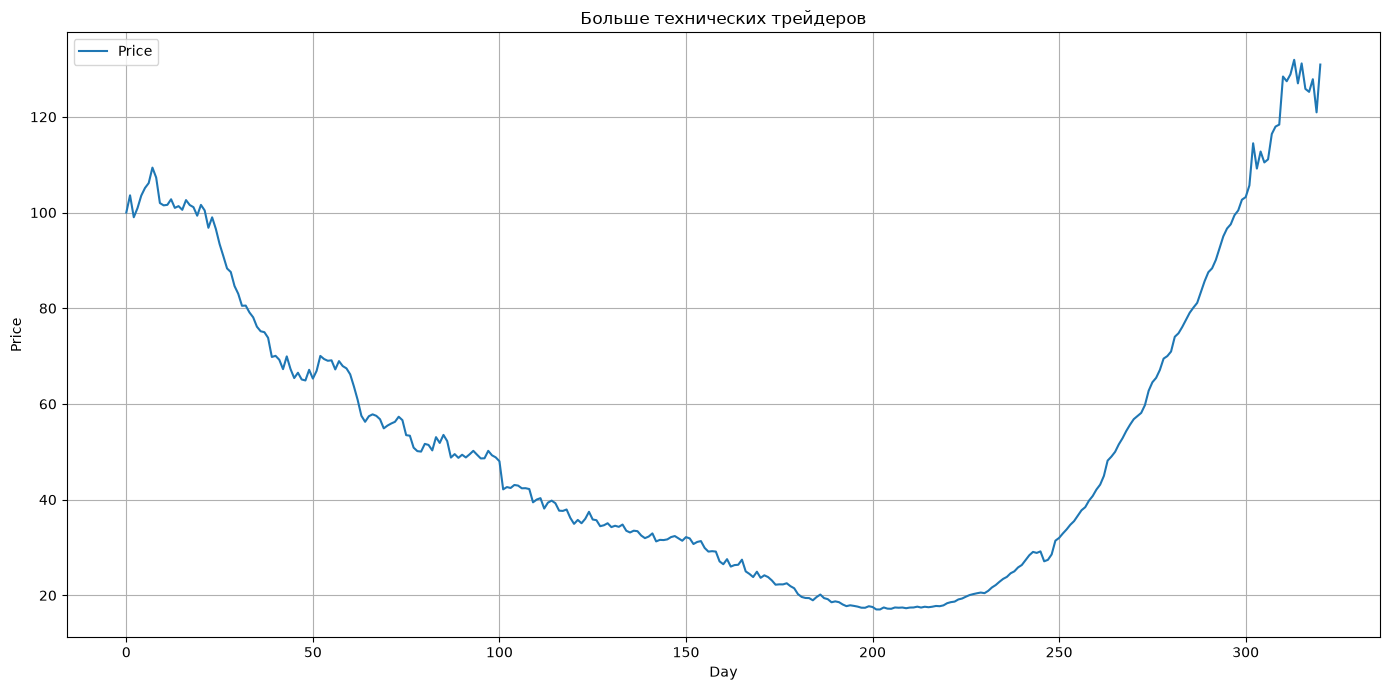

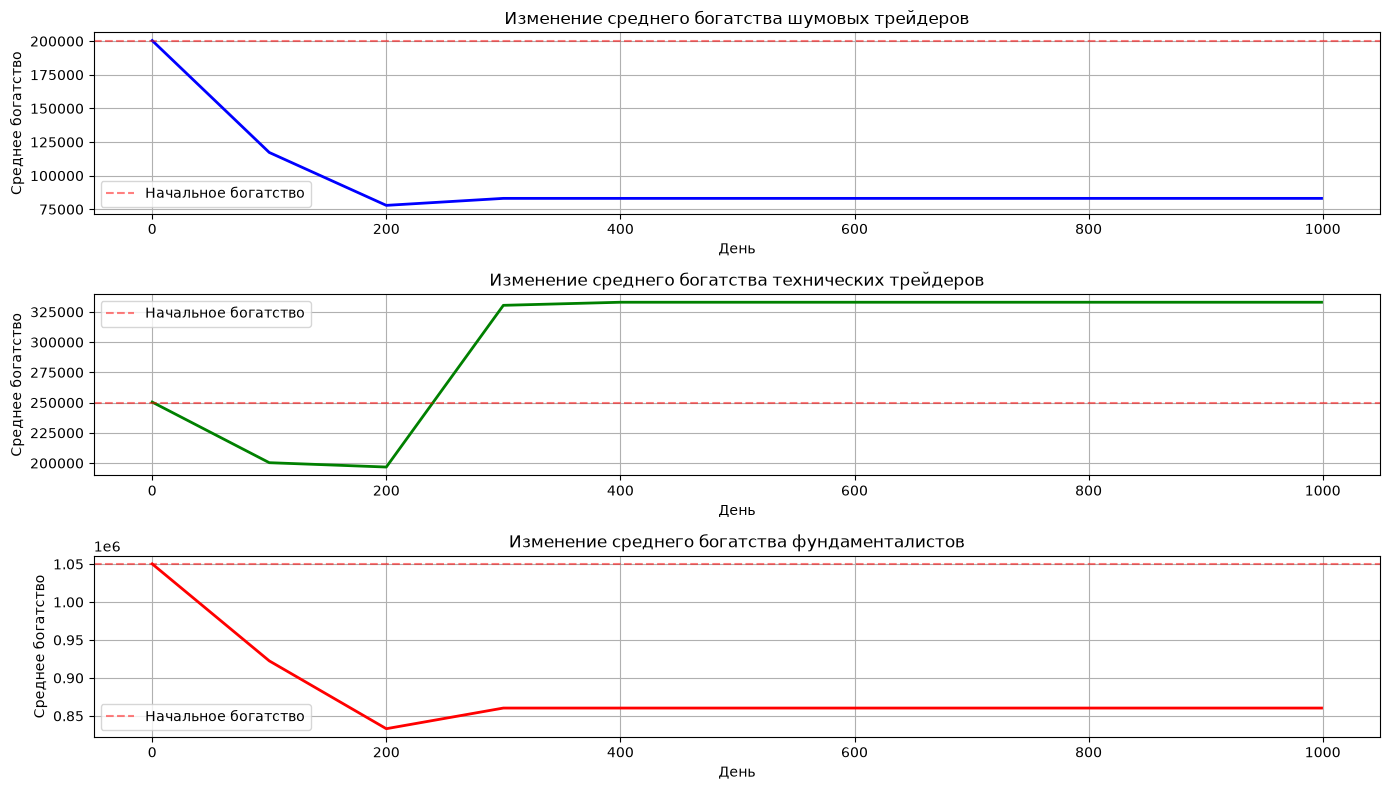

In [7]:
np.random.seed(SEED)
asset, traders = simulation.run_simulation(SCENARIOS['more_chartists'], days=DAYS)
plot_price(asset, title=SCENARIOS['more_chartists'].title)
plot_wealth_history(simulation.wealth_history)
plt.show()

Вновь взглянем на гистограммы распределений совокупного богатства у различных типов трейдеров:

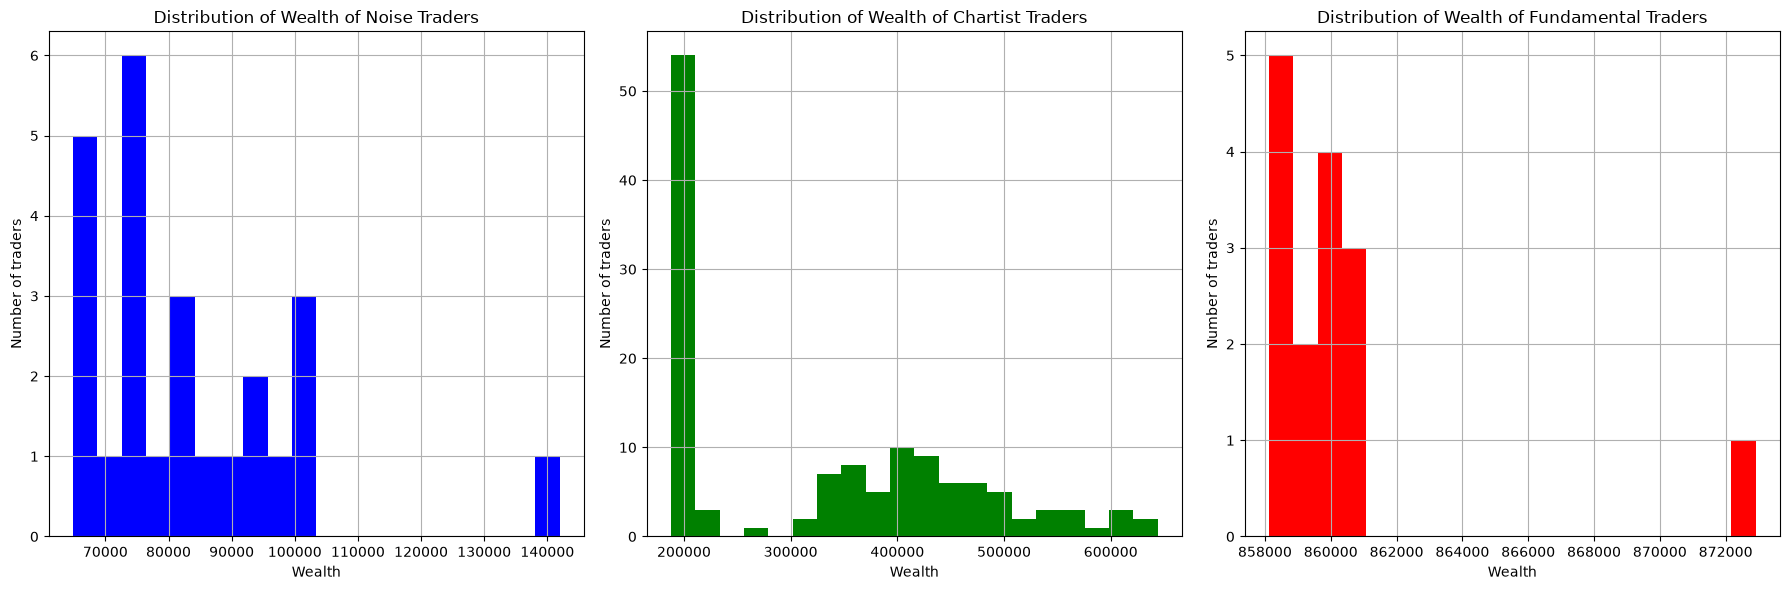

In [8]:
plot_wealth_histograms(traders)
plt.show()

Теперь же увеличим количество фундаменталистов в 10 раз:


Day 0: Price = 101.14
Active Traders - Noise: 50/50, Chartist: 20/20, Fundamentalist: 300/300
Noise Traders: Avg Cash = 98989.69, Avg Assets = 1010.00, Avg Wealth = 201140.41
Chartist Traders: Avg Cash = 152525.77, Avg Assets = 975.00, Avg Wealth = 251136.61
Fundamentalist Traders: Avg Cash = 1000000.00, Avg Assets = 500.00, Avg Wealth = 1050569.66

Day 100: Price = 69.97
Active Traders - Noise: 50/50, Chartist: 20/20, Fundamentalist: 300/300
Noise Traders: Avg Cash = 123847.64, Avg Assets = 656.20, Avg Wealth = 169762.17
Chartist Traders: Avg Cash = 161438.14, Avg Assets = 839.50, Avg Wealth = 220178.24
Fundamentalist Traders: Avg Cash = 995262.85, Avg Assets = 568.00, Avg Wealth = 1035006.00

Day 200: Price = 151.49
Active Traders - Noise: 50/50, Chartist: 20/20, Fundamentalist: 300/300
Noise Traders: Avg Cash = 177145.86, Avg Assets = 29.74, Avg Wealth = 181651.28
Chartist Traders: Avg Cash = 64288.20, Avg Assets = 1739.55, Avg Wealth = 327819.35
Fundamentalist Traders: Avg Cash = 

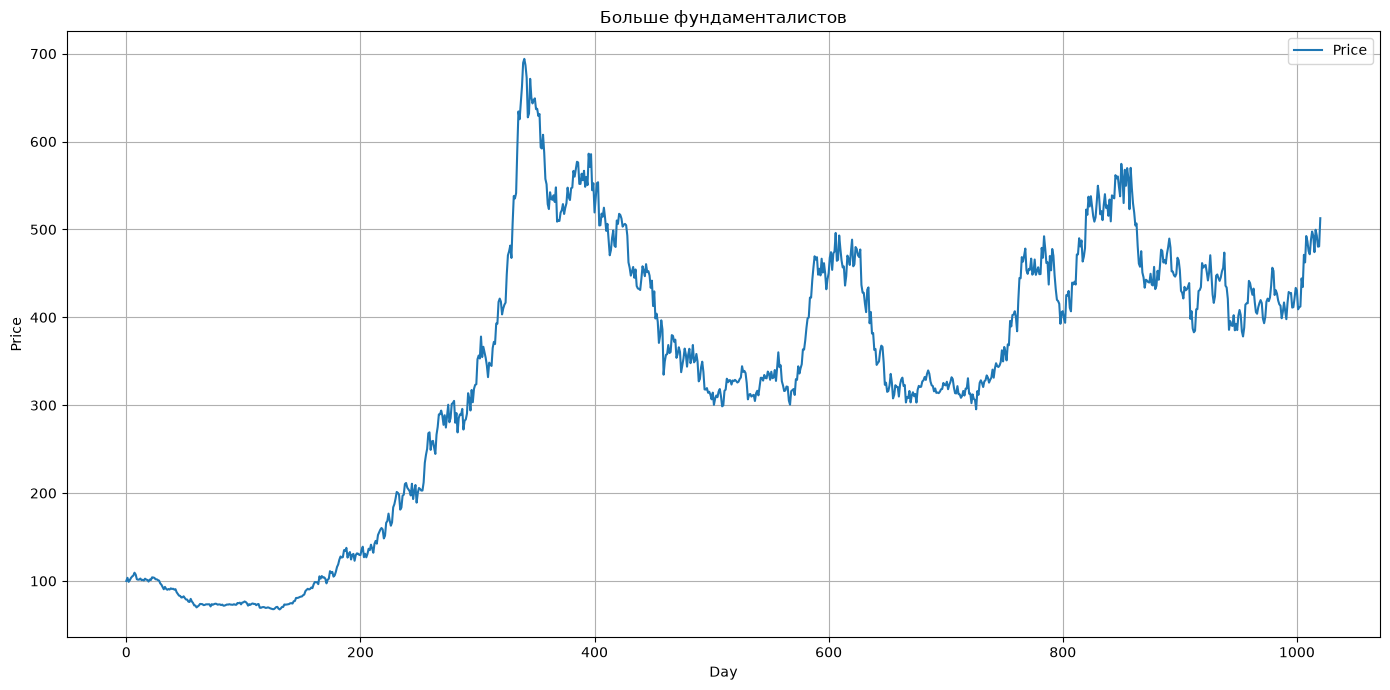

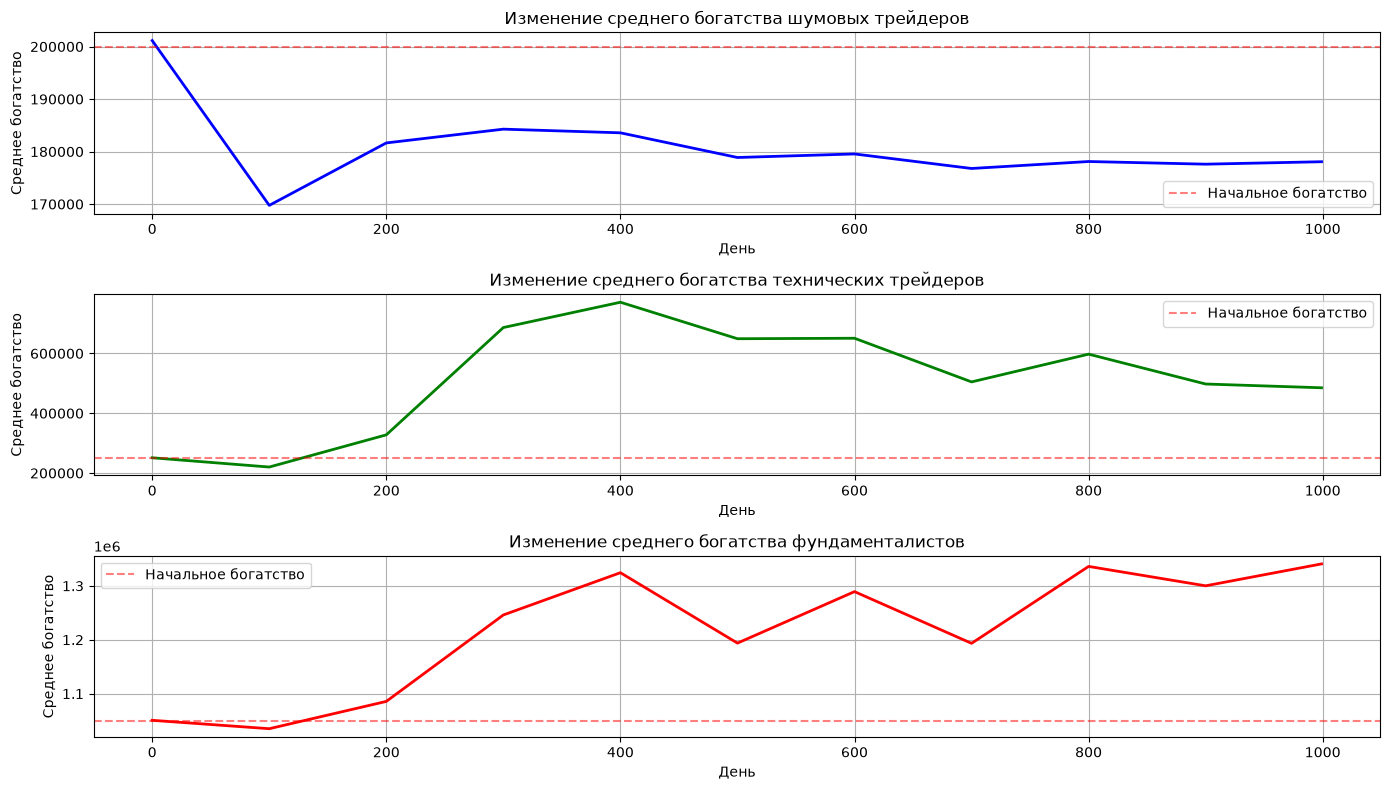

In [9]:
np.random.seed(SEED)
asset, traders = simulation.run_simulation(SCENARIOS['more_fundamentalists'], days=DAYS)
plot_price(asset, title=SCENARIOS['more_fundamentalists'].title)
plot_wealth_history(simulation.wealth_history)
plt.show()

Взглянем на гистограммы распределений совокупного богатства:

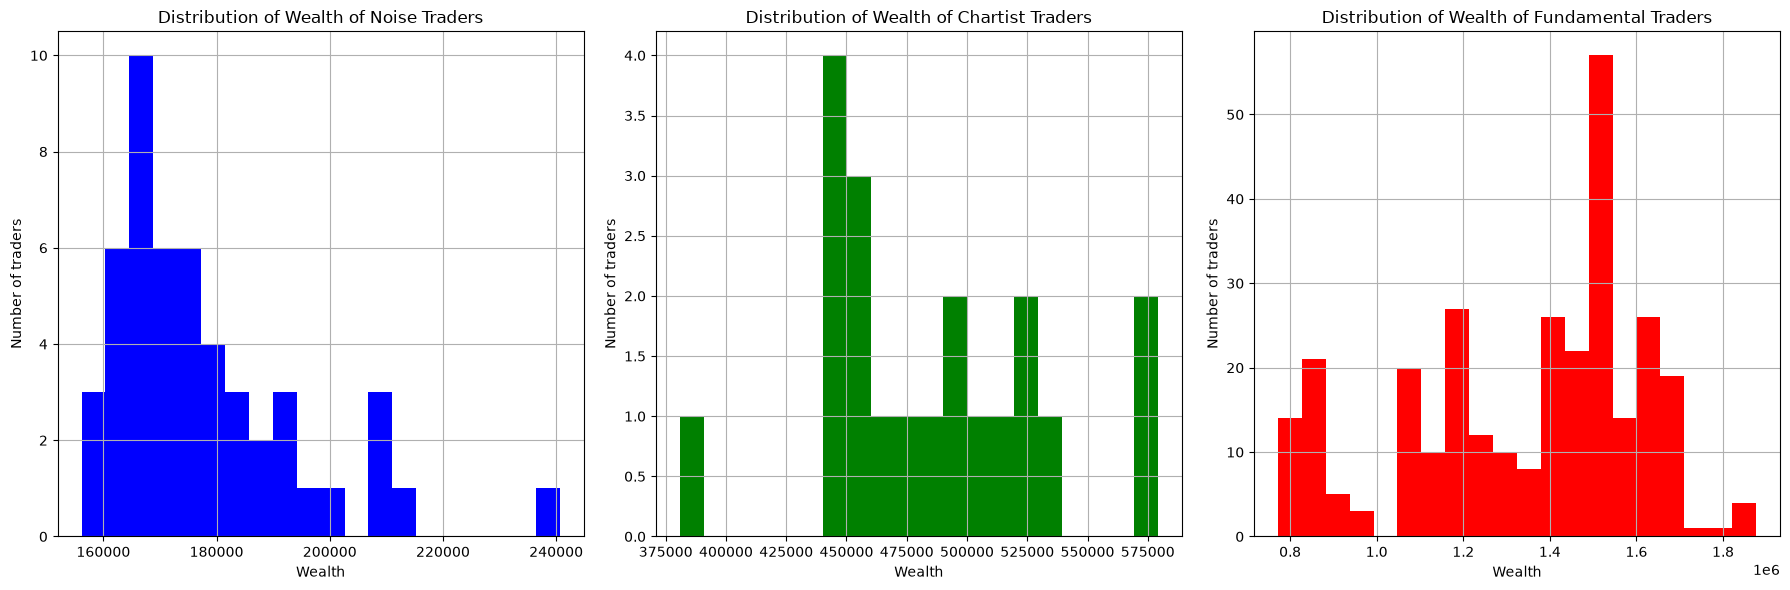

In [10]:
plot_wealth_histograms(traders)
plt.show()

На этот раз модифицируем базовую агентную модель посредством добавления остановки торгов в случае, если цена бумаги в какой-либо день отличается на 20% от цены предыдущего дня. Для этого необходимо модифицировать класс функций актива, книги заявок и запуска симуляции модели, остальные классы можно оставить без изменений. Сделаем это ниже:

In the package this is `SCENARIOS['circuit_breaker']`: `Asset(circuit_breaker=True)` rejects a price update that moves more than 20% from the last checked price, and the loop calls `check_halt_status()` every day, skipping trading while the halt lasts.


Day 0: Price = 101.14
Active Traders - Noise: 50/50, Chartist: 20/20, Fundamentalist: 30/30
Noise Traders: Avg Cash = 98989.69, Avg Assets = 1010.00, Avg Wealth = 201140.41
Chartist Traders: Avg Cash = 152525.77, Avg Assets = 975.00, Avg Wealth = 251136.61
Fundamentalist Traders: Avg Cash = 1000000.00, Avg Assets = 500.00, Avg Wealth = 1050569.66

Day 100: Price = 69.97
Active Traders - Noise: 50/50, Chartist: 20/20, Fundamentalist: 30/30
Noise Traders: Avg Cash = 123847.64, Avg Assets = 656.20, Avg Wealth = 169762.17
Chartist Traders: Avg Cash = 161438.14, Avg Assets = 839.50, Avg Wealth = 220178.24
Fundamentalist Traders: Avg Cash = 952628.51, Avg Assets = 1180.00, Avg Wealth = 1035193.50

Day 200: Price = 135.35
Active Traders - Noise: 50/50, Chartist: 20/20, Fundamentalist: 30/30
Noise Traders: Avg Cash = 171511.21, Avg Assets = 88.54, Avg Wealth = 183494.70
Chartist Traders: Avg Cash = 171392.25, Avg Assets = 644.30, Avg Wealth = 258595.40
Fundamentalist Traders: Avg Cash = 86655

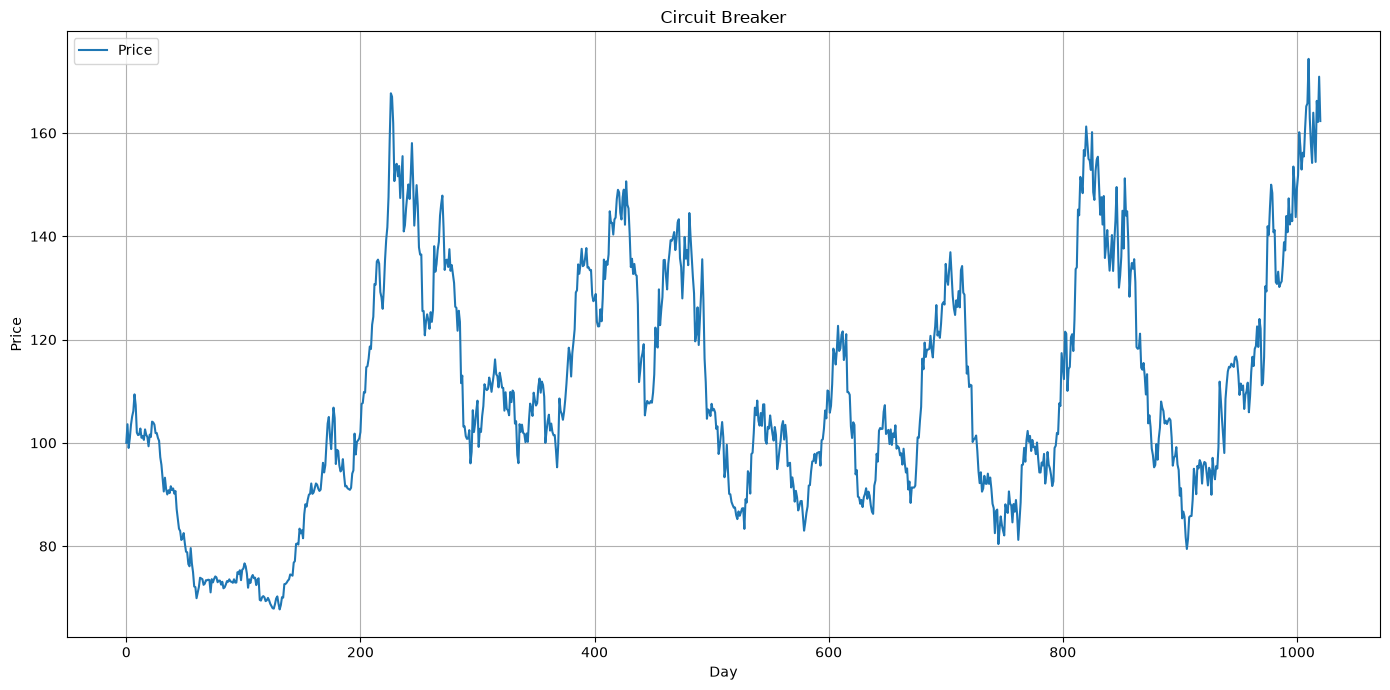

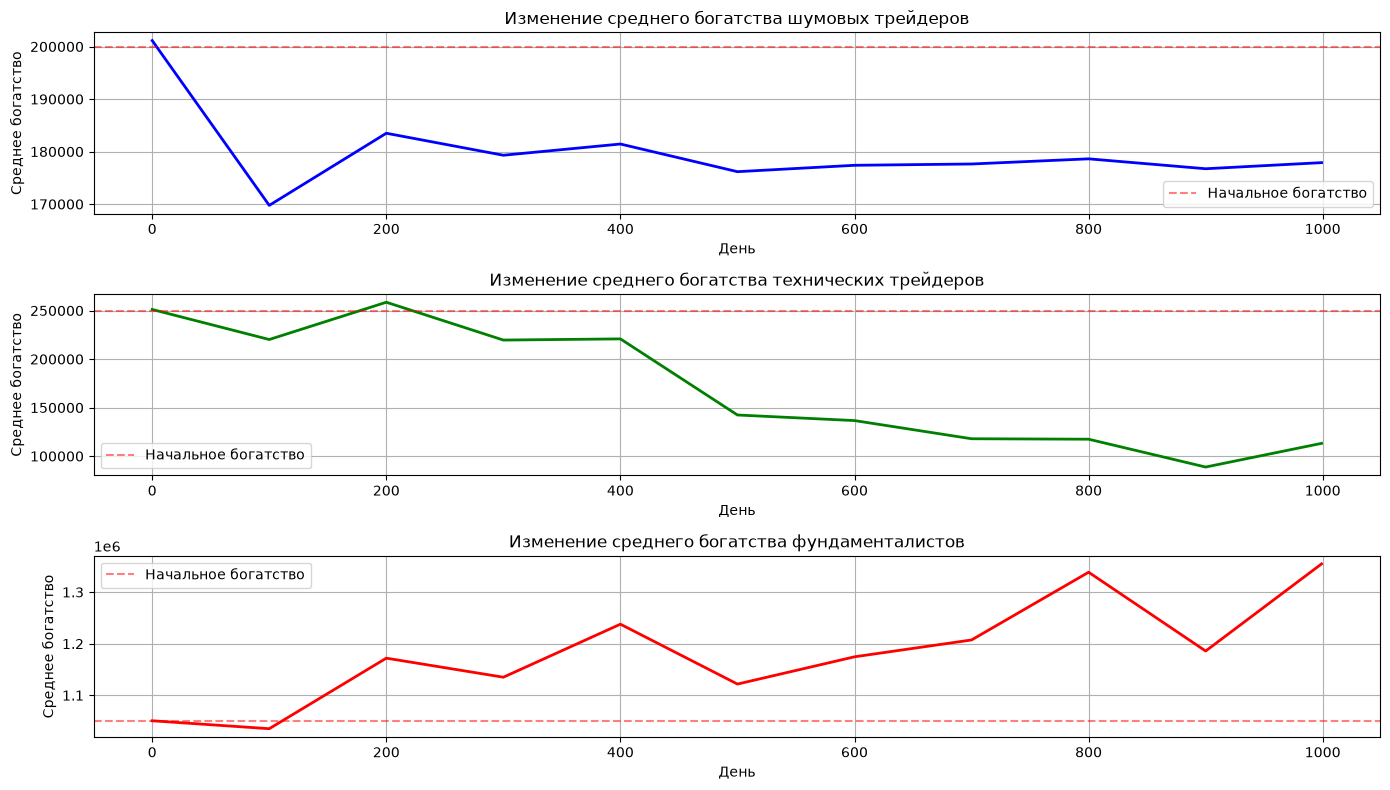

In [11]:
np.random.seed(SEED)
asset, traders = simulation.run_simulation(SCENARIOS['circuit_breaker'], days=DAYS)
plot_price(asset, title=SCENARIOS['circuit_breaker'].title, show_halts=True)
plot_wealth_history(simulation.wealth_history)
plt.show()

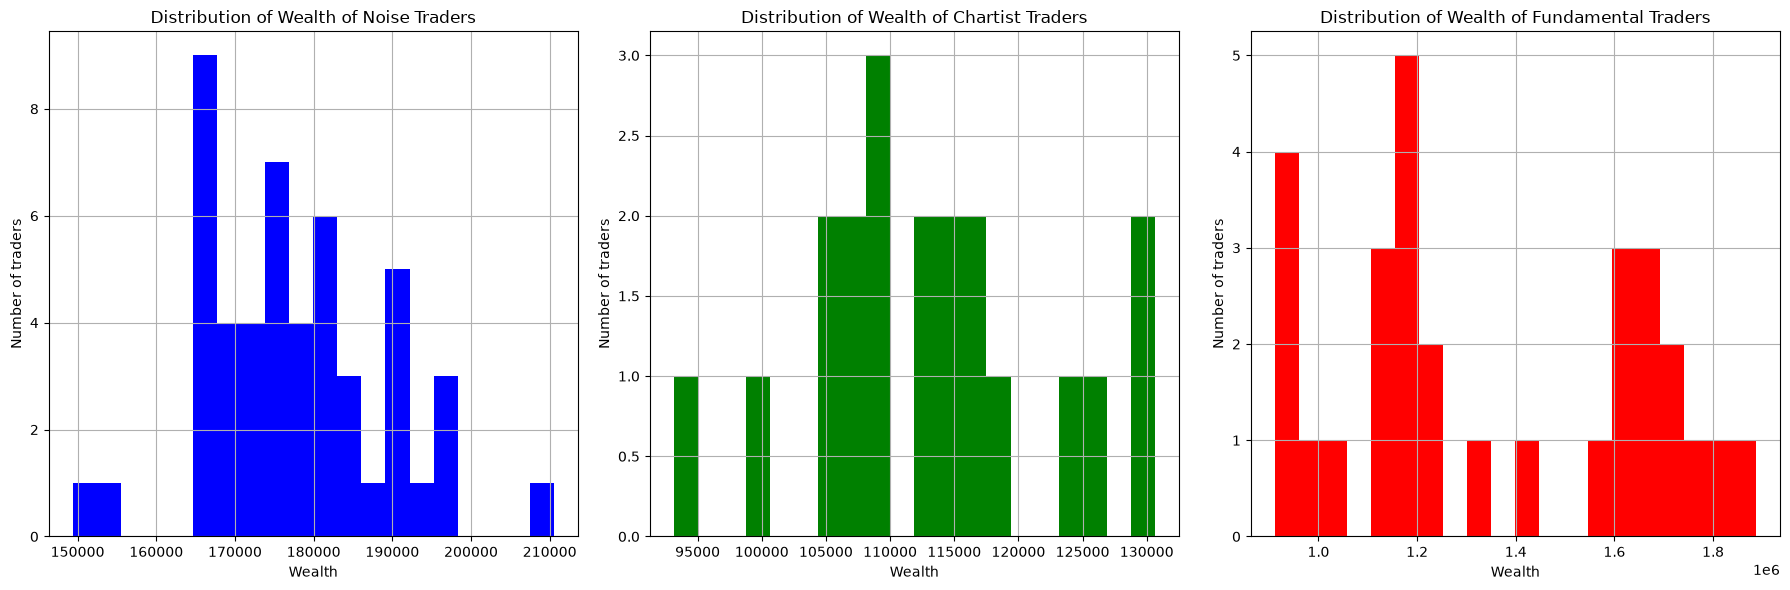

In [12]:
plot_wealth_histograms(traders)
plt.show()

Теперь же расширим модель и применим для нее эволюцию трейдеров - каждые 100 дней(каждый период) 2 случайных шумовых трейдера становятся чартистами, а также 1 чартист становится фундаменталистом:

Note: in the original notebook the circuit-breaker `Asset` from the previous section was still defined when this scenario ran, but the halt check was never called. `SCENARIOS['evolution']` keeps that configuration so results stay comparable.


Day 0: Price = 101.14
Active Traders - Noise: 50/50, Chartist: 20/20, Fundamentalist: 30/30
Noise Traders: Avg Cash = 98989.69, Avg Assets = 1010.00, Avg Wealth = 201140.41
Chartist Traders: Avg Cash = 152525.77, Avg Assets = 975.00, Avg Wealth = 251136.61
Fundamentalist Traders: Avg Cash = 1000000.00, Avg Assets = 500.00, Avg Wealth = 1050569.66

Circuit Breaker: Торги остановлены на 5 дней (изменение 21.08% > 20.00%)

Эволюция трейдеров на день 100
Шумовой трейдер эволюционировал в чартиста (активы: 261, cash: 158728.67)
Шумовой трейдер эволюционировал в чартиста (активы: 1297, cash: 77112.88)
Чартист эволюционировал в фундаменталиста (активы: 817, cash: 165143.80)

Day 100: Price = 68.85
Active Traders - Noise: 48/50, Chartist: 21/20, Fundamentalist: 31/30
Noise Traders: Avg Cash = 120675.36, Avg Assets = 704.29, Avg Wealth = 169167.41
Chartist Traders: Avg Cash = 161247.88, Avg Assets = 775.00, Avg Wealth = 214608.35
Fundamentalist Traders: Avg Cash = 929721.85, Avg Assets = 1126.

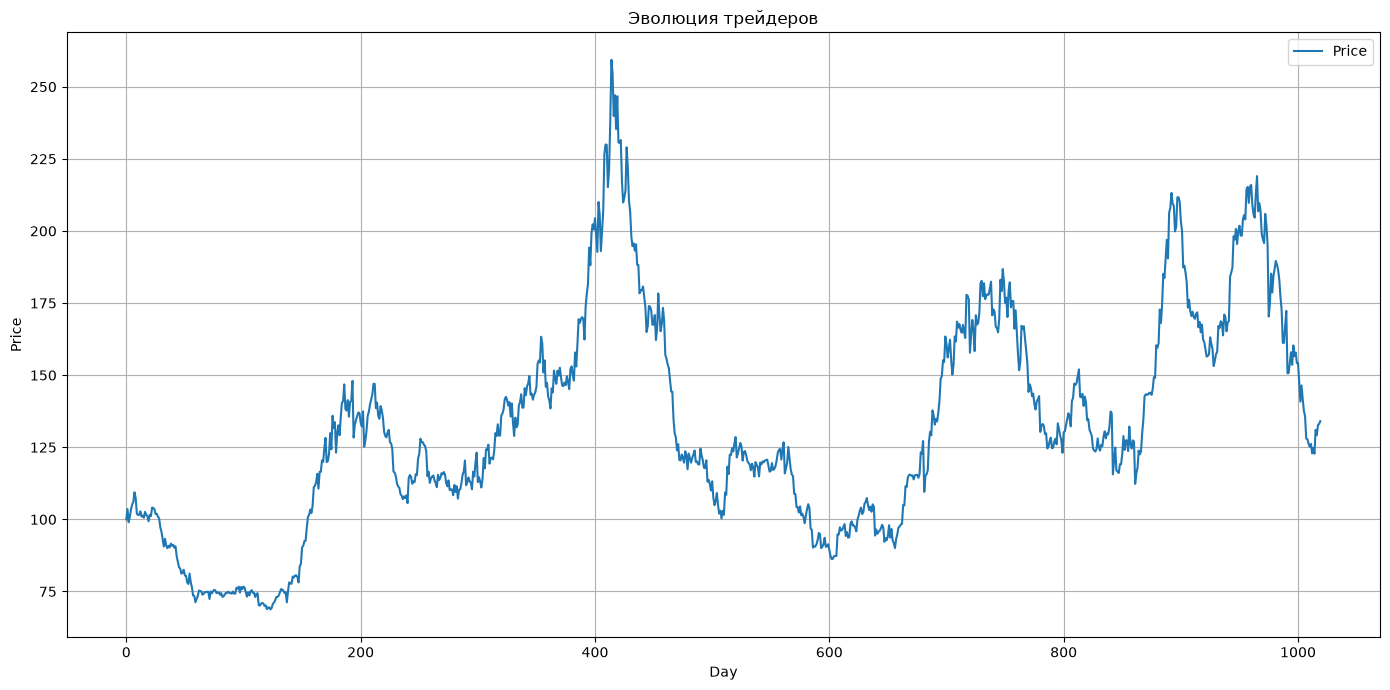

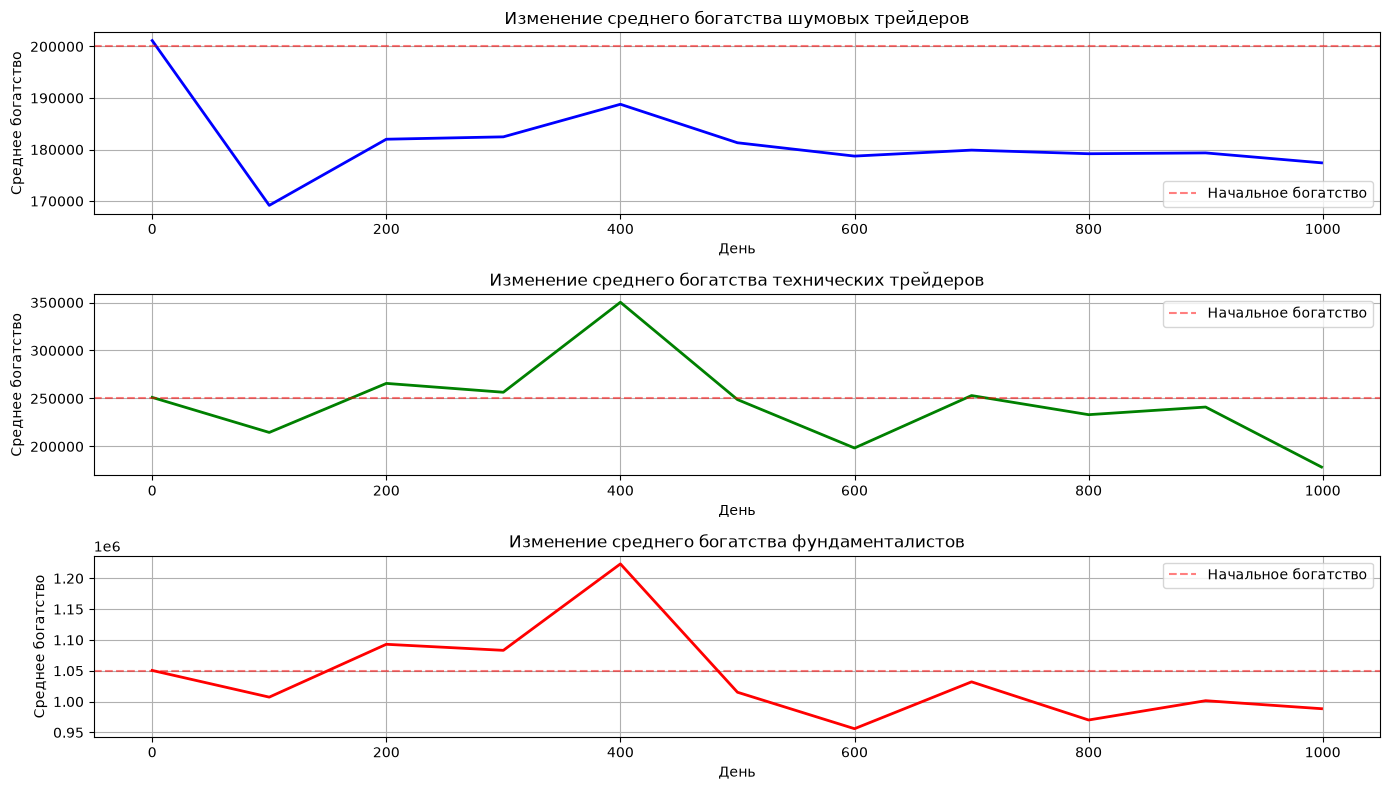

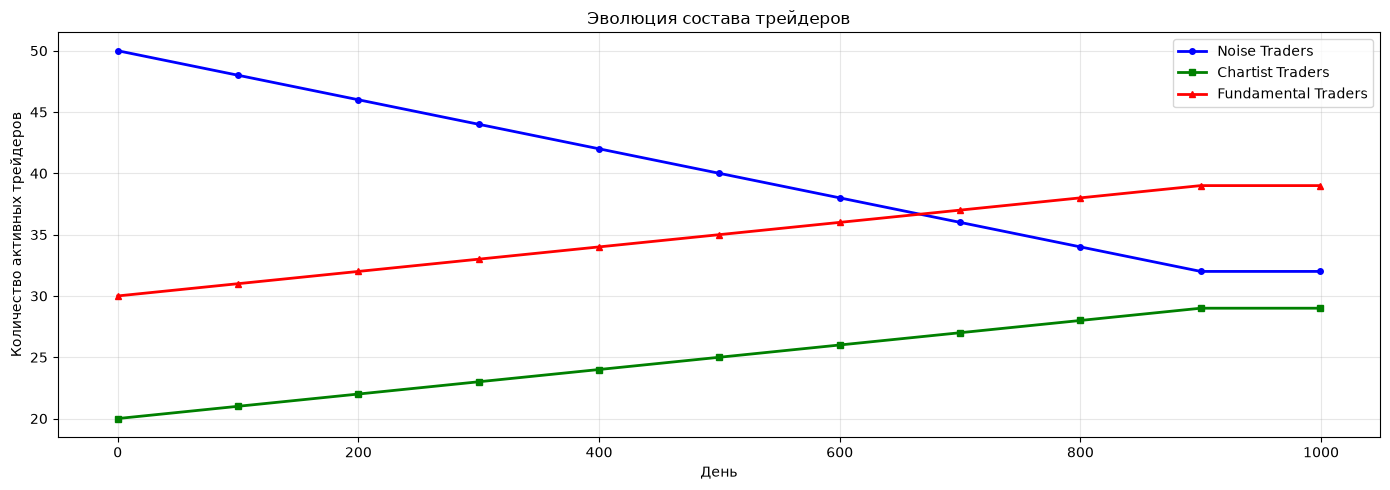

In [13]:
np.random.seed(SEED)
asset, traders = simulation.run_simulation(SCENARIOS['evolution'], days=DAYS)
plot_price(asset, title=SCENARIOS['evolution'].title)
plot_wealth_history(simulation.wealth_history)
plot_trader_counts(asset)
plt.show()

Также построим гистограммы распределений богатств, хотя в данном случае они не очень интересны:

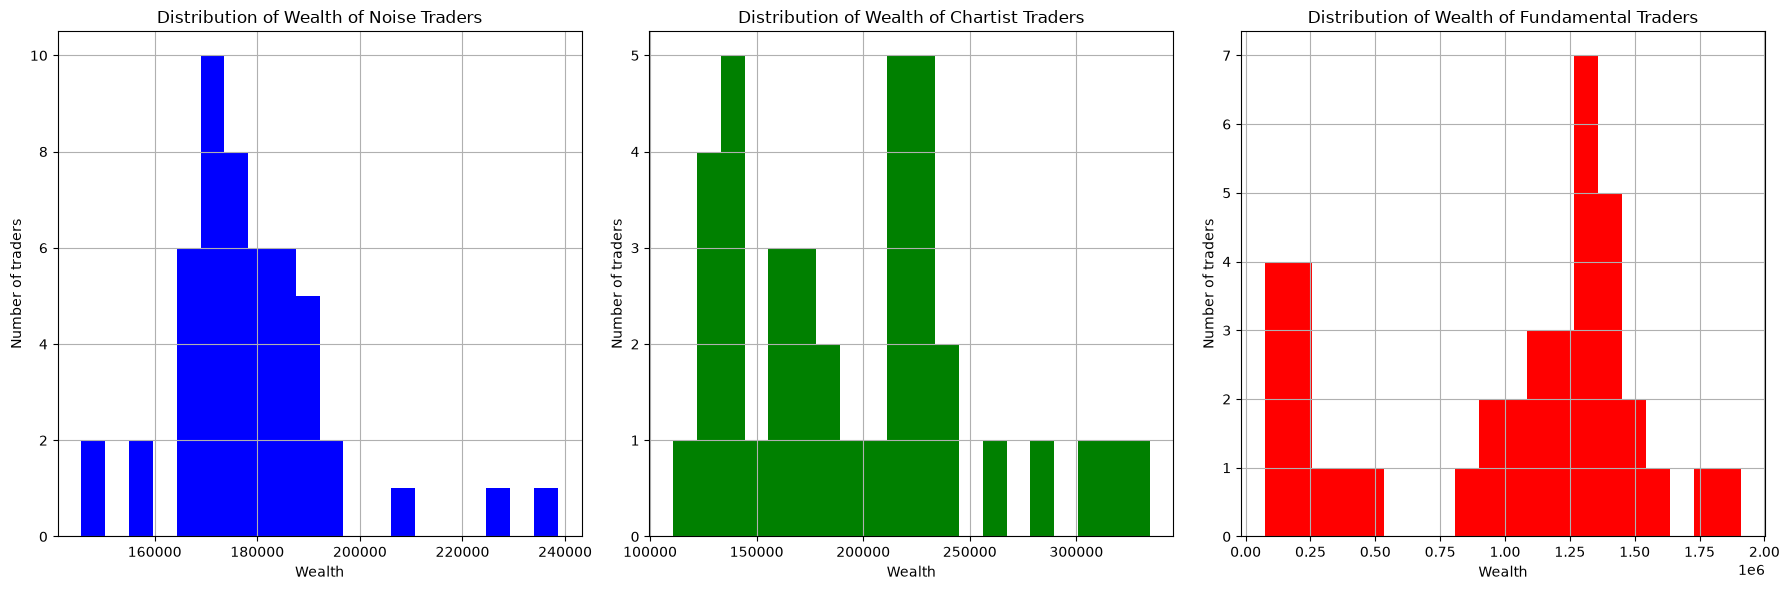

In [14]:
plot_wealth_histograms(traders)
plt.show()

Теперь посчитаем значения показателя Херста, Ляпунова и Энтропию Колмогорова-Синую на примере индекса РТС, ММВБ, S&P 500, DJIA, NASDAQ за период 09.05.2016 - 09.05.2026.

Для начала подгрузим данные:

In [15]:
import os

indices = {name: load_index(os.path.join(DATA_DIR, file)) for name, file in INDEX_FILES.items()}
indices['РТС']

,Дата,Цена
0,2026-05-08,1101.49
1,2026-05-07,1104.09
2,2026-05-06,1102.42
3,2026-05-05,1105.63
4,2026-05-04,1094.42
...,...,...
2504,2016-05-16,929.12
2505,2016-05-13,921.88
2506,2016-05-12,915.95
2507,2016-05-11,927.00


Посчитаем указанные метрики:

In [16]:
for name, data in indices.items():
    print_index_metrics(name, index_metrics(data['Цена'].values))


РТС
Показатель Херста: 0.5328
Показатель Ляпунова: 0.003440
Энтропия Колмогорова-Синая: 1.601361 бит/шаг

ММВБ
Показатель Херста: 0.5378
Показатель Ляпунова: 0.000930
Энтропия Колмогорова-Синая: 1.517753 бит/шаг

S&P500
Показатель Херста: 0.5168
Показатель Ляпунова: 0.013124
Энтропия Колмогорова-Синая: 1.410588 бит/шаг

DJIA
Показатель Херста: 0.5159
Показатель Ляпунова: 0.002696
Энтропия Колмогорова-Синая: 1.470639 бит/шаг


/home/roman/Desktop/abm_chaos/Agent_modelling/.venv/lib/python3.12/site-packages/sklearn/metrics/_regression.py:1295: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
/home/roman/Desktop/abm_chaos/Agent_modelling/.venv/lib/python3.12/site-packages/sklearn/metrics/_regression.py:1295: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)



NASDAQ
Показатель Херста: 0.5077
Показатель Ляпунова: 0.003362
Энтропия Колмогорова-Синая: 1.503435 бит/шаг
